In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/05_hotel_bookings.csv")

In [8]:
df.shape

(25000, 15)

In [9]:
df.head()

,hotel,is_canceled,lead_time,arrival_date,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,agent,adr,total_of_special_requests
0,Resort Hotel,0,342,2015-07-01,0,0,2,0.0,0,BB,PRT,Direct,NaN,0.00,0
1,Resort Hotel,0,13,2015-07-01,0,1,1,0.0,0,BB,GBR,Corporate,304.0,75.00,0
2,Resort Hotel,0,72,2015-07-01,2,4,2,0.0,0,BB,PRT,Direct,250.0,99.67,1
3,Resort Hotel,0,95,2015-07-01,4,11,2,0.0,0,BB,GBR,Offline TA/TO,241.0,63.86,0
4,Resort Hotel,1,40,2015-07-02,1,3,3,0.0,0,BB,PRT,Online TA,241.0,108.80,1


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   hotel                      25000 non-null  object 
 1   is_canceled                25000 non-null  int64  
 2   lead_time                  25000 non-null  int64  
 3   arrival_date               25000 non-null  object 
 4   stays_in_weekend_nights    25000 non-null  int64  
 5   stays_in_week_nights       25000 non-null  int64  
 6   adults                     25000 non-null  int64  
 7   children                   25000 non-null  float64
 8   babies                     25000 non-null  int64  
 9   meal                       25000 non-null  object 
 10  country                    24884 non-null  object 
 11  market_segment             25000 non-null  object 
 12  agent                      21553 non-null  float64
 13  adr                        25000 non-null  flo

In [12]:
df.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0
children,0
babies,0
meal,0


In [13]:
df.duplicated().sum()

np.int64(4772)

In [14]:
df.describe()

,is_canceled,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,agent,adr,total_of_special_requests
count,25000.000000,25000.00000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,21553.000000,25000.000000,25000.000000
mean,0.375840,104.33964,0.928840,2.498920,1.855800,0.104080,0.007680,86.814968,101.489893,0.566920
std,0.484349,106.84183,0.993446,1.896244,0.603905,0.399467,0.104792,110.726455,47.706437,0.793339
min,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,0.000000,18.00000,0.000000,1.000000,2.000000,0.000000,0.000000,9.000000,68.450000,0.000000
50%,0.000000,70.00000,1.000000,2.000000,2.000000,0.000000,0.000000,14.000000,94.500000,0.000000
75%,1.000000,161.00000,2.000000,3.000000,2.000000,0.000000,0.000000,229.000000,125.100000,1.000000
max,1.000000,629.00000,19.000000,50.000000,55.000000,3.000000,9.000000,531.000000,451.500000,5.000000


In [15]:
df['hotel'].value_counts()

,count
hotel,
City Hotel,16521
Resort Hotel,8479


In [16]:
df['is_canceled'].value_counts()

,count
is_canceled,
0,15604
1,9396


In [32]:
df['is_canceled'].value_counts(normalize=True) * 100

,proportion
is_canceled,
0,62.416
1,37.584


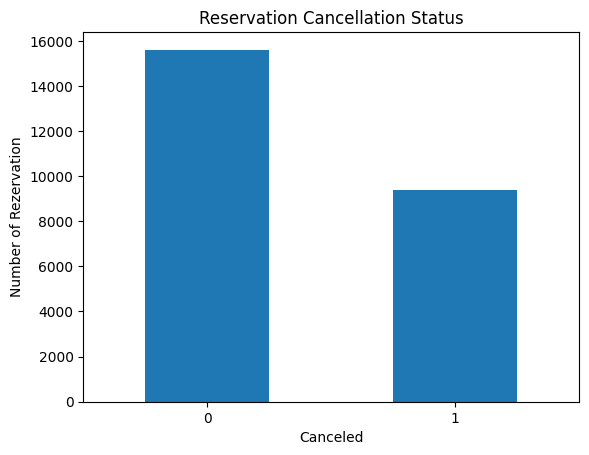

In [26]:
canceled = df['is_canceled'].value_counts().sort_index().plot(kind='bar', title='Reservation Cancellation Status', xlabel='Canceled', ylabel='Number of Rezervation')
canceled = plt.xticks(rotation=0)

In [30]:
df.groupby('hotel')['is_canceled'].mean() * 100

,is_canceled
hotel,
City Hotel,42.570062
Resort Hotel,27.868852


In [33]:
df['lead_time'].describe()

,lead_time
count,25000.00000
mean,104.33964
std,106.84183
min,0.00000
25%,18.00000
50%,70.00000
75%,161.00000
max,629.00000


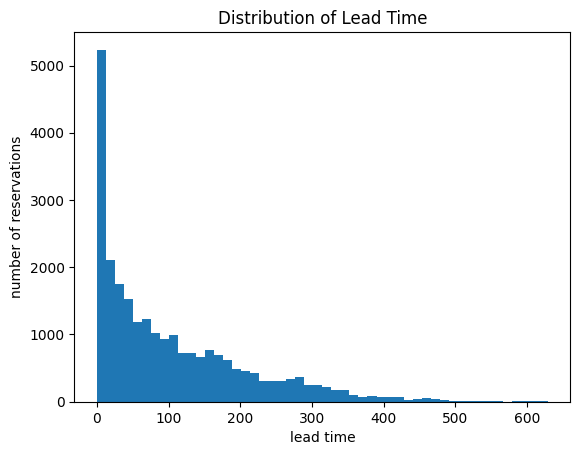

In [41]:
ld_time = df['lead_time'].plot(kind='hist', bins=50, title='Distribution of Lead Time', xlabel='lead time', ylabel='number of reservations')

In [42]:
df['lead_group'] = pd.cut(df['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 1000], labels=['0-7', '8-30', '31-90', '91-180', '181-365', '365+'])

In [44]:
cancel_by_lead = df.groupby('lead_group', observed=True)['is_canceled'].mean() * 100
cancel_by_lead

,is_canceled
lead_group,
0-7,9.506619
8-30,28.237684
31-90,37.844898
91-180,46.179996
181-365,56.200353
365+,67.019667


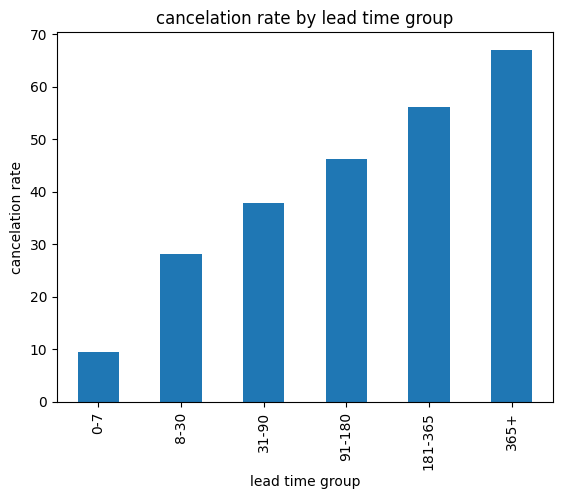

In [46]:
cancel_by_lead.plot(kind='bar', title='cancelation rate by lead time group', xlabel='lead time group', ylabel='cancelation rate');

In [49]:
df.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0
children,0
babies,0
meal,0


In [50]:
df['is_canceled'].mean() * 100

np.float64(37.584)

In [51]:
df.drop_duplicates()['is_canceled'].mean() * 100

np.float64(30.19576824204074)

In [53]:
(df['adr'] == 0).sum()

np.int64(367)

In [54]:
(df['adults'] == 0).sum()

np.int64(83)

In [55]:
((df['stays_in_week_nights'] + df['stays_in_weekend_nights']) == 0).sum()

np.int64(130)

In [58]:
df_clean = df.drop_duplicates().copy()
df_clean.shape

(20228, 16)

In [59]:
df_clean['lead_group'] = pd.cut(df['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 1000], labels=['0-7', '8-30', '31-90', '91-180', '181-365', '365+'])

In [60]:
df_clean.groupby('lead_group', observed=True)['is_canceled'].mean() * 100

,is_canceled
lead_group,
0-7,9.025361
8-30,26.369392
31-90,33.359238
91-180,38.170928
181-365,44.849334
365+,57.575758


In [65]:
df_clean['total_nights'] = df_clean['stays_in_week_nights'] + df_clean['stays_in_weekend_nights']
df_clean['nights_group'] = pd.cut(df_clean['total_nights'], bins=[-1, 0, 1, 3, 7, 14, 100], labels=['0', '1', '2-3', '4-7', '8-14', '15+'])
df_clean.groupby('nights_group', observed=True)['is_canceled'].mean() * 100

,is_canceled
nights_group,
0,1.612903
1,20.513472
2-3,33.044017
4-7,32.340789
8-14,32.608696
15+,45.945946


In [68]:
df_clean.groupby('market_segment')['is_canceled'].agg(['mean', 'count']).sort_values('mean')

,mean,count
market_segment,,
Complementary,0.125874,143
Direct,0.141978,2599
Corporate,0.143430,997
Offline TA/TO,0.200988,3443
Aviation,0.217391,46
Online TA,0.368091,11326
Groups,0.422342,1674


In [69]:
df_clean.groupby('total_of_special_requests')['is_canceled'].mean() * 100

,is_canceled
total_of_special_requests,
0,37.352358
1,22.955145
2,22.133028
3,18.016194
4,9.638554
5,0.000000


In [70]:
df_clean.groupby('is_canceled')['adr'].agg(['mean', 'median'])

,mean,median
is_canceled,,
0,100.820382,94.0
1,113.302988,105.3


<Axes: title={'center': 'Cancellation Rate by Market Segment'}, xlabel='Cancellation rate'>

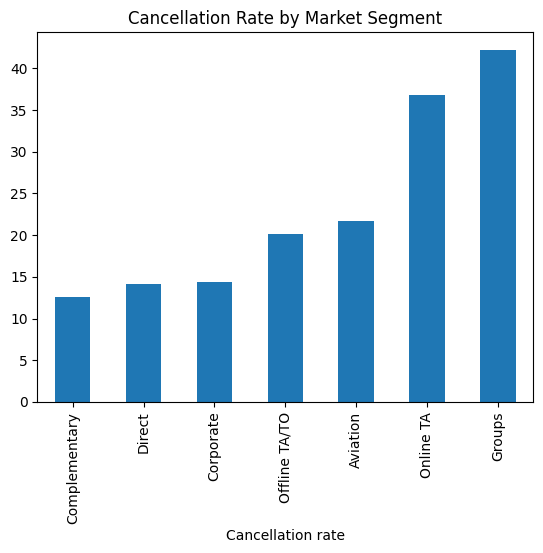

In [74]:
seg = df_clean.groupby('market_segment')['is_canceled'].mean().sort_values() * 100
seg.plot(kind='bar', title='Cancellation Rate by Market Segment', xlabel='Cancellation rate')

<Axes: title={'center': 'Correlation with Cancellation'}, xlabel='Correlation'>

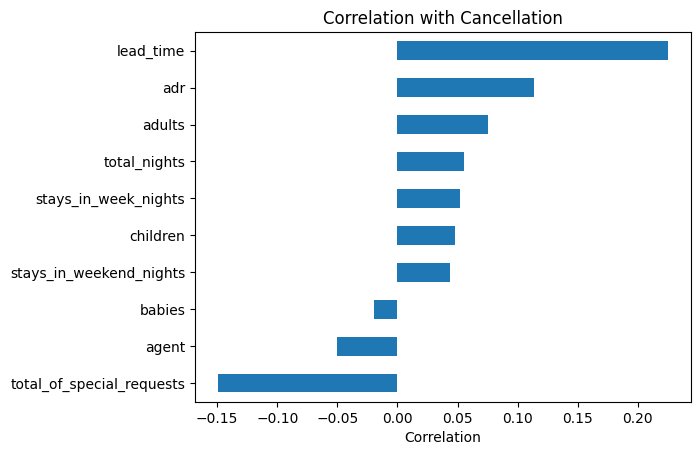

In [85]:
import matplotlib.pyplot as plt

corr = df_clean.select_dtypes('number').corr()['is_canceled'].drop('is_canceled').sort_values()
corr.plot(kind='barh', title='Correlation with Cancellation', xlabel='Correlation')